In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Project root not found")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
OUT = ROOT / "data" / "processed"
RESULTS = ROOT / "experiments" / "results"

from backend.detection.evaluation.evaluate import evaluate_scores
from backend.detection.evaluation.metrics import ranking_metrics
from backend.detection.models.isolation_forest import IsolationForestDetector
from backend.detection.models.one_class_svm import OneClassSVMDetector
from backend.detection.models.pca import PCADetector
from backend.detection.models.statistical import ZScoreDetector

data = np.load(OUT / "hdfs_features.npz")
X_int, y = data["X"], data["y"]
X = X_int.astype(float)
train_normal, val, test = data["train_normal"], data["validation"], data["test"]
splits = {"validation": val, "test": test}

keys = [row.tobytes() for row in X_int]
train_keys = {keys[i] for i in train_normal}
novel = np.array([k not in train_keys for k in keys])   # vector never seen among training normals
print(f"Training normal blocks: {len(train_normal):,}   distinct vectors: {len(train_keys)}")

Training normal blocks: 333,878   distinct vectors: 207


# 05 — HDFS model comparison (RQ1)

All models trained on normal training blocks; same split, thresholds and metrics for every model.
- B4: lookup table (Day 14), as a score (1 = vector never seen among training normals)
- z-score, PCA (Day 15), Isolation Forest, One-Class SVM (deduplicated + weighted)
Thresholds: label-free p99.9 (no labels) and validation-tuned (best F1 on validation).

In [2]:
rng = np.random.default_rng(0)
rows = []
for n in (16_000, 64_000, len(train_normal)):
    idx = train_normal if n == len(train_normal) else rng.choice(train_normal, size=n, replace=False)
    row = {"training blocks": n}
    for deduplicate in (False, True):
        label = "deduplicated" if deduplicate else "full"
        start = time.time()
        model = OneClassSVMDetector(nu=0.01, deduplicate=deduplicate).fit(X[idx])
        row[f"fit s ({label})"] = round(time.time() - start, 2)
        row[f"rows trained ({label})"] = model.n_training_rows_
        row[f"support vectors ({label})"] = len(model.model_.support_)
    rows.append(row)
display(pd.DataFrame(rows))

,training blocks,fit s (full),rows trained (full),support vectors (full),fit s (deduplicated),rows trained (deduplicated),support vectors (deduplicated)
0,16000,0.14,16000,166,0.05,101,30
1,64000,2.57,64000,644,0.31,145,48
2,333878,188.02,333878,3345,2.03,207,93


In [3]:
rows = []
for nu in (0.001, 0.005, 0.01, 0.05, 0.1):
    model = OneClassSVMDetector(nu=nu).fit(X[train_normal])
    rows.append({"nu": nu, "validation_pr_auc": round(ranking_metrics(y[val], model.score(X[val]))["pr_auc"], 4)})
nu_table = pd.DataFrame(rows)
display(nu_table)
best_nu = float(nu_table.loc[nu_table["validation_pr_auc"].idxmax(), "nu"])
print("Chosen nu:", best_nu)

,nu,validation_pr_auc
0,0.001,0.9966
1,0.005,0.9956
2,0.010,0.9812
3,0.050,0.9380
4,0.100,0.9309


Chosen nu: 0.001


In [4]:
models = {
    "z-score": ZScoreDetector(),
    "PCA": PCADetector(variance=0.95),
    "Isolation Forest": IsolationForestDetector(n_estimators=200, random_state=42),
    "One-Class SVM": OneClassSVMDetector(nu=best_nu),
}
scores = {"B4 lookup": novel.astype(float)}
timing = []
for name, model in models.items():
    start = time.time()
    model.fit(X[train_normal])
    fitted = time.time()
    scores[name] = model.score(X)
    timing.append({"model": name, "fit_s": round(fitted - start, 2), "score_575k_s": round(time.time() - fitted, 2)})
display(pd.DataFrame(timing))

,model,fit_s,score_575k_s
0,z-score,0.07,0.11
1,PCA,0.33,0.20
2,Isolation Forest,0.68,4.50
3,One-Class SVM,1.86,3.62


In [5]:
rows = []
for name, s in scores.items():
    rows += evaluate_scores(name, s, y, train_normal, splits, novel=novel)
results = pd.DataFrame(rows)
results["novel_normal_flagged"] = (results["novel_normal_flagged"].astype(str) + "/" +
                                   results["novel_normal_total"].astype(str))
results = results.drop(columns="novel_normal_total")

show = ["model", "threshold", "precision", "recall", "f1", "fp", "fn", "pr_auc", "novel_normal_flagged"]
for part in ("validation", "test"):
    print(f"\n=== {part} ===")
    display(results[results["split"] == part][show].round(4))


=== validation ===


,model,threshold,precision,recall,f1,fp,fn,pr_auc,novel_normal_flagged
0,B4 lookup,label-free p99.9,0.9993,1.0000,0.9996,3,0,0.9993,3/3
2,B4 lookup,validation-tuned,0.9993,1.0000,0.9996,3,0,0.9993,3/3
4,z-score,label-free p99.9,0.2411,0.0067,0.0131,85,3974,0.5471,2/3
6,z-score,validation-tuned,0.8464,0.4874,0.6186,354,2051,0.5471,3/3
8,PCA,label-free p99.9,0.9986,0.8930,0.9429,5,428,0.9951,1/3
10,PCA,validation-tuned,0.9732,1.0000,0.9864,110,0,0.9951,3/3
12,Isolation Forest,label-free p99.9,0.0000,0.0000,0.0000,54,4001,0.1379,0/3
14,Isolation Forest,validation-tuned,0.2059,0.9773,0.3402,15076,91,0.1379,3/3
16,One-Class SVM,label-free p99.9,0.9901,0.9995,0.9948,40,2,0.9966,3/3
18,One-Class SVM,validation-tuned,0.9968,0.9995,0.9981,13,2,0.9966,3/3



=== test ===


,model,threshold,precision,recall,f1,fp,fn,pr_auc,novel_normal_flagged
1,B4 lookup,label-free p99.9,0.9562,1.0000,0.9776,77,0,0.9562,77/77
3,B4 lookup,validation-tuned,0.9562,1.0000,0.9776,77,0,0.9562,77/77
5,z-score,label-free p99.9,0.2857,0.0012,0.0024,5,1677,0.7562,0/77
7,z-score,validation-tuned,0.7831,0.7653,0.7741,356,394,0.7562,0/77
9,PCA,label-free p99.9,0.9524,0.9774,0.9647,82,38,0.9947,77/77
11,PCA,validation-tuned,0.9230,1.0000,0.9600,140,0,0.9947,77/77
13,Isolation Forest,label-free p99.9,0.0000,0.0000,0.0000,39,1679,0.0180,1/77
15,Isolation Forest,validation-tuned,0.0230,0.9637,0.0449,68827,61,0.0180,77/77
17,One-Class SVM,label-free p99.9,0.9433,1.0000,0.9708,101,0,0.9988,77/77
19,One-Class SVM,validation-tuned,0.9529,1.0000,0.9759,83,0,0.9988,77/77


In [6]:
final = (results[results["split"] == "test"]
         .pivot_table(index="model", columns="threshold", values="f1")
         .rename(columns=lambda c: f"F1 {c}"))
final["PR-AUC"] = results[results["split"] == "test"].groupby("model")["pr_auc"].first()
final = final.sort_values("F1 label-free p99.9", ascending=False).round(4)
display(final)

results.to_csv(RESULTS / "hdfs_model_comparison.csv", index=False)
final.to_csv(RESULTS / "hdfs_model_comparison_summary.csv")
print("Saved hdfs_model_comparison.csv and hdfs_model_comparison_summary.csv")

threshold,F1 label-free p99.9,F1 validation-tuned,PR-AUC
model,,,
B4 lookup,0.9776,0.9776,0.9562
One-Class SVM,0.9708,0.9759,0.9988
PCA,0.9647,0.9600,0.9947
z-score,0.0024,0.7741,0.7562
Isolation Forest,0.0000,0.0449,0.0180


Saved hdfs_model_comparison.csv and hdfs_model_comparison_summary.csv


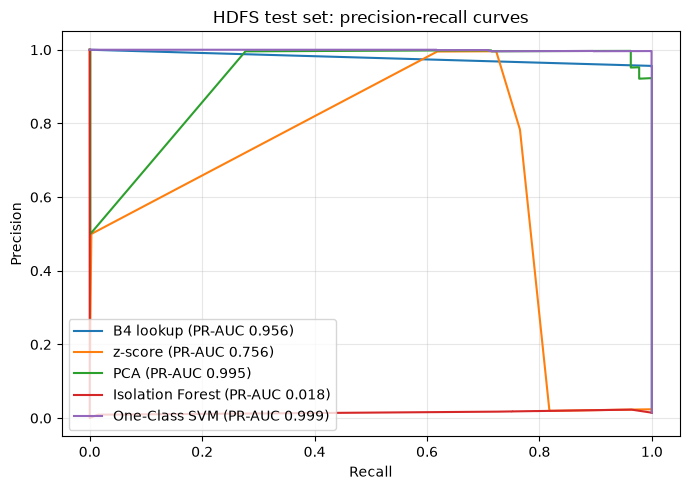

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, s in scores.items():
    precision, recall, _ = precision_recall_curve(y[test], s[test])
    ax.plot(recall, precision, label=f"{name} (PR-AUC {ranking_metrics(y[test], s[test])['pr_auc']:.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("HDFS test set: precision-recall curves")
ax.legend(loc="lower left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS / "hdfs_pr_curves.png", dpi=150)
plt.show()

In [10]:
feature_names = list(data["feature_names"])
std = X[train_normal].std(axis=0)
constant = [name for name, s in zip(feature_names, std) if s == 0]
print(f"{len(constant)} of {len(feature_names)} features never vary among training normal blocks:")
print(constant, "\n")

typical = X[train_normal][:1].copy()
probe = typical.copy()
probe[0, feature_names.index("unseen")] = 5

for name in ("Isolation Forest", "PCA", "One-Class SVM"):
    model = models[name]
    print(f"{name:<17} typical block {model.score(typical)[0]:>10.4f}   "
          f"+5 unseen events {model.score(probe)[0]:>10.4f}")

4 of 20 features never vary among training normal blocks:
[np.str_('E2'), np.str_('E3'), np.str_('E4'), np.str_('unseen')] 

Isolation Forest  typical block     0.7229   +5 unseen events     0.7229
PCA               typical block    96.8479   +5 unseen events   196.8479
One-Class SVM     typical block    30.2616   +5 unseen events    42.6437


## Findings
- Test F1 (label-free p99.9 / validation-tuned) and PR-AUC:
  B4 lookup 0.978 / 0.978 / 0.956; One-Class SVM 0.971 / 0.976 / 0.999; PCA 0.965 / 0.960 / 0.995;
  z-score 0.002 / 0.774 / 0.756; Isolation Forest 0.000 / 0.045 / 0.018.
- One-Class SVM gives the best ranking of all methods (PR-AUC 0.999), but no model beats the lookup
  table on F1: HDFS is close to solved by memorisation. OCSVM and PCA add graded scores.
- Models that use relationships between counts (OCSVM, PCA) work; z-score and Isolation Forest do not.
- One-Class SVM training time grew super-linearly (16k→64k blocks: 4x data, 18x time; 64k→334k: 5.2x data,
  73x time). Training on the 207 distinct vectors weighted by frequency: 188 s → 2 s (~93x),
  3,345 → 93 support vectors.
- Isolation Forest diagnostic: 4 of 20 features (E2, E3, E4, unseen) never vary among training normals.
  Adding 5 unseen events left the IF score unchanged (0.7229 → 0.7229), while PCA (96.8 → 196.8) and
  OCSVM (30.3 → 42.6) increased. IF cannot split on features constant in training, and these are exactly
  the HDFS anomaly signals (new templates; missing write-completion events E3/E4).
- All working models flag the same 77 novel normal test blocks: candidates for error analysis.